# HW1 : Regression
Instructions: https://www.cs.tufts.edu/cs/135/2026s/hw1.html

In [1]:
%pip install numpy pandas scikit-learn matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [2]:


import os
import numpy as np
import pandas as pd
 
import sklearn.preprocessing
import sklearn.pipeline
import sklearn.linear_model

In [3]:
from matplotlib import pyplot as plt

import seaborn as sns
#This sets the default style for all figures. 
sns.set('notebook', font_scale=1.25, style='whitegrid')

### Loading the data

Make sure `dataset_auto.csv` is in the same directory as this notebook

In [4]:
# Let's look at the first few lines of the data file.

with open('dataset_auto.csv', 'r') as f:
    for line in f.readlines()[:5]:
        print(line.strip())

mpg,cylinders,displacement,horsepower,weight,acceleration,year,origin,name
18,8,307,130,3504,12,70,1,chevrolet chevelle malibu
15,8,350,165,3693,11.5,70,1,buick skylark 320
18,8,318,150,3436,11,70,1,plymouth satellite
16,8,304,150,3433,12,70,1,amc rebel sst


In [5]:
# A richer examination of the dataset is included in the day01 Pandas/Matplotlib lab.
# We want to drop rows with missing horsepower values (represented by '?') and then
# grab the columns of interest: mpg (0), displacement (2) and horsepower (3)

auto_arr = np.loadtxt('dataset_auto.csv', delimiter=',', skiprows=1, dtype=str)
auto_arr = auto_arr[auto_arr[:,3] != '?']
auto_arr = np.asarray(auto_arr[:,[0,2,3]], dtype=np.float64)

### Methods for loading dataset

In [6]:
# the last column of our 3-column data set is horsepower
x_N_horsepower = auto_arr[:,2]

# your linear model expects an input of size (N,1)
x_N1_horsepower = x_N_horsepower[:,np.newaxis] 

# the firs two columns are mpg and displacement
y_N_mpg = auto_arr[:,0]
y_N_displacement = auto_arr[:,1]

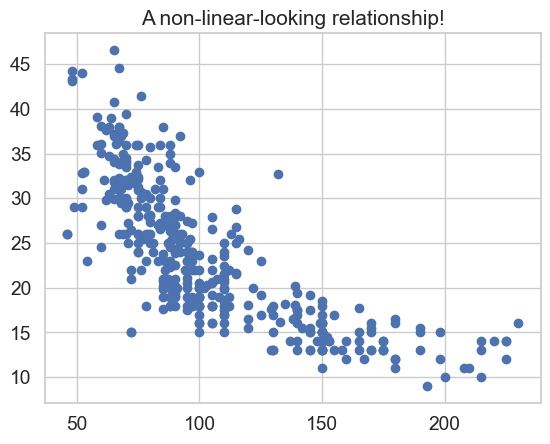

In [7]:
plt.scatter(x_N_horsepower, y_N_mpg)
plt.title("A non-linear-looking relationship!")
plt.show()

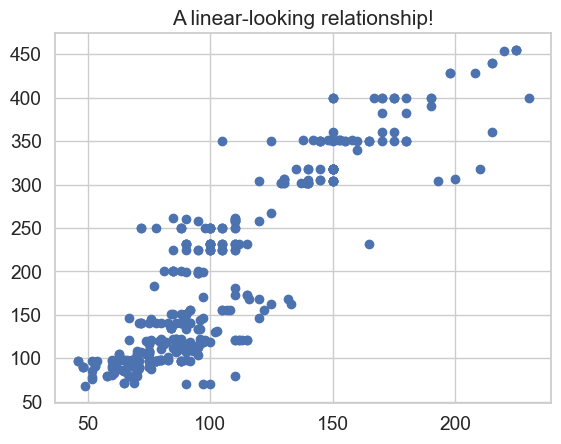

In [8]:
plt.scatter(x_N_horsepower, y_N_displacement)
plt.title("A linear-looking relationship!")
plt.show()

# Fitting a parabola

The provided code constructs a quadratic regression model and fits it to the hosepower-mpg problem. We can visualize the fit parabola by evaluating it on a dense grid of points; the commented-out line of code which produces the parabola will raise errors until you've finished your implementation.

In [9]:
from LeastSquaresQuadraticRegression import LeastSquaresQuadraticRegressor

quad_regr = LeastSquaresQuadraticRegressor()
quad_regr.fit(x_N_horsepower, y_N_mpg)

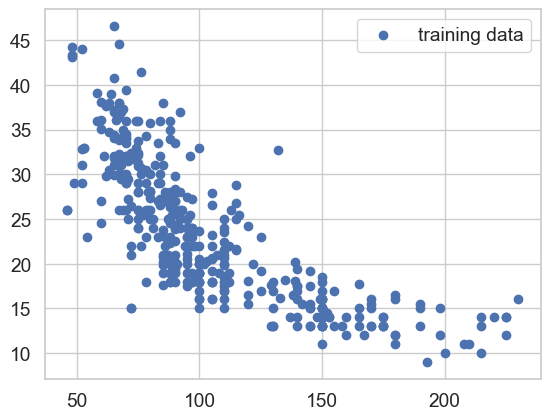

In [10]:
grid = np.linspace(50,250, 100)
y_hats = quad_regr.predict(grid)

plt.scatter(x_N_horsepower, y_N_mpg, label='training data')
# plt.plot(grid, y_hats, label='fit parabola', color='red')
plt.legend()
plt.show()

There's plenty more to do, but you'll have to write the code yourself! Remember you need to compute the rMSE of a line and a parabola on the 2 regression problems mentioned in the assignment instructions.

In [15]:
from LeastSquaresLinearRegression import LeastSquaresLinearRegressor
from performance_metrics import calc_root_mean_squared_error

# linear reg: you need mpg and horsepower
# the last column of our 3-column data set is horsepower
x_N_horsepower = auto_arr[:,2]

# your linear model expects an input of size (N,1)
x_N1_horsepower = x_N_horsepower[:,np.newaxis] 

# the firs two columns are mpg and displacement
y_N_mpg = auto_arr[:,0]
y_N_displacement = auto_arr[:,1]

lin_mpg = LeastSquaresLinearRegressor()
lin_mpg.fit(x_N1_horsepower, y_N_mpg)
yhat_mpg_lin = lin_mpg.predict(x_N1_horsepower)
rmse_mpg_lin = calc_root_mean_squared_error(y_N_mpg, yhat_mpg_lin)


quad_regr_mpg = LeastSquaresQuadraticRegressor()
quad_regr_mpg.fit(x_N_horsepower, y_N_mpg)
y_pred_mpg_quad = quad_regr_mpg.predict(x_N_horsepower)
rmse_mpg_quad = calc_root_mean_squared_error(y_N_mpg, y_pred_mpg_quad)

lin_disp = LeastSquaresLinearRegressor()
lin_disp.fit(x_N1_horsepower, y_N_displacement)
yhat_disp_lin = lin_disp.predict(x_N1_horsepower)
rmse_disp_lin = calc_root_mean_squared_error(y_N_displacement, yhat_disp_lin)

# Quadratic Model
quad_disp = LeastSquaresQuadraticRegressor()
quad_disp.fit(x_N1_horsepower, y_N_displacement)
yhat_disp_quad = quad_disp.predict(x_N1_horsepower)
rmse_disp_quad = calc_root_mean_squared_error(y_N_displacement, yhat_disp_quad)

print("rsme1", rmse_mpg_lin)
print("rsme2", rmse_mpg_quad)
print("rsme3", rmse_disp_lin)
print("rsme4", rmse_disp_quad)

rsme1 4.893226230065713
rsme2 4.3571514671419465
rsme3 46.142263300853244
rsme4 45.530056216651005
